# 09 — Hai pipeline đã khóa trên 3.101 patch PALSAR

Đây là phép thử bổ sung trên toàn bộ `external_train` của manifest SOS.
Tên `train` do nhà phát hành đặt; pipeline hiện tại fit/chọn cấu hình trên
Sentinel train/validation. Không fit lại hoặc chọn tham số từ kết quả này.
Không có mã cảnh để chứng minh độc lập theo cảnh; không trộn với 776 ảnh
PALSAR `external_val` đã đánh giá trước đó.

Chuẩn bị từ thư mục gốc:
```text
python scripts/audit_palsar_holdout.py
python scripts/evaluate_palsar_holdout.py --prepare
python scripts/evaluate_palsar_holdout.py --run --workers 4
python scripts/report_palsar_holdout.py
```
Nguồn: [Refined SOS v1](https://zenodo.org/records/15298010).
Ô đầu kiểm tra đủ ảnh, hash và tổng hợp lại số đếm; chưa đủ sẽ dừng.

In [1]:
from pathlib import Path
import json, sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/sar_oil').is_dir())
sys.path.insert(0,str(ROOT/'scripts'))
from report_palsar_holdout import verified_results
result=verified_results()
protocol=json.loads((ROOT/'results/sos/external_palsar_train/protocol.json').read_text())
print('Verified images per pipeline:', {name:r['completed'] for name,r in result.items()})
print('Scene independence: not established')

Verified images per pipeline: {'otsu': 3101, 'niblack': 3101}
Scene independence: not established


## Kết quả toàn tập theo cùng quy tắc ghép đối tượng

Mask tham chiếu ≥128; liên thông 8; ghép một-một tại IoU ≥0,5.
Micro Precision, Recall và F1 tính từ tổng TP, FP, FN, không lấy trung bình F1
của từng ảnh. Hai pipeline khác cả bộ lọc/tham số và classifier; bảng này không
tách được tác dụng riêng của thuật toán phân ngưỡng. Không dùng để chọn lại mô hình.

| Pipeline | TP | FP | FN | Precision | Recall | F1 | IoU pixel |
|---|---:|---:|---:|---:|---:|---:|---:|
| otsu | 6170 | 11014 | 12978 | 0.359055 | 0.322227 | 0.339645 | 0.641096 |
| niblack | 5180 | 17199 | 13968 | 0.231467 | 0.270524 | 0.249476 | 0.494529 |

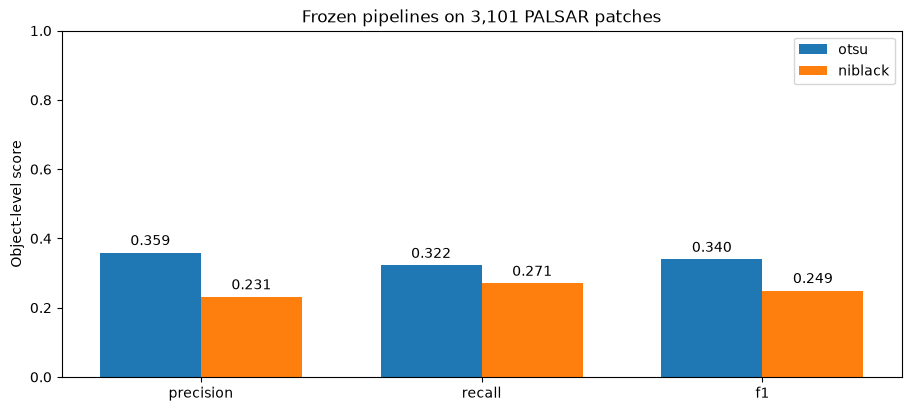

In [2]:
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import numpy as np
lines=['| Pipeline | TP | FP | FN | Precision | Recall | F1 | IoU pixel |',
       '|---|---:|---:|---:|---:|---:|---:|---:|']
for name,r in result.items():
    m=r['metrics']
    lines.append(f"| {name} | {m['tp']} | {m['fp']} | {m['fn']} | {m['precision']:.6f} | {m['recall']:.6f} | {m['f1']:.6f} | {m['pixel_iou']:.6f} |")
display(Markdown(chr(10).join(lines)))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
keys=['precision','recall','f1'];x=np.arange(len(keys))
for i,(name,r) in enumerate(result.items()):
    values=[r['metrics'][k] for k in keys]
    bars=ax.bar(x+(i-.5)*.36,values,.36,label=name)
    ax.bar_label(bars,fmt='%.3f',padding=3)
ax.set_xticks(x,keys);ax.set_ylim(0,1);ax.set_ylabel('Object-level score')
ax.set_title('Frozen pipelines on 3,101 PALSAR patches');ax.legend()
plt.show()

## Một ảnh minh họa theo quy tắc cố định

Chọn ID nhỏ nhất theo thứ tự từ điển trong toàn tập, không chọn theo điểm mô
hình. Đọc ảnh và mask thật, chạy lại cả hai pipeline, đối chiếu toàn bộ số đếm
của ảnh với kết quả đã lưu. Đây là một ví dụ, không đại diện hiệu năng toàn tập.
Mask tham chiếu chỉ đưa vào phép chấm điểm sau suy luận.

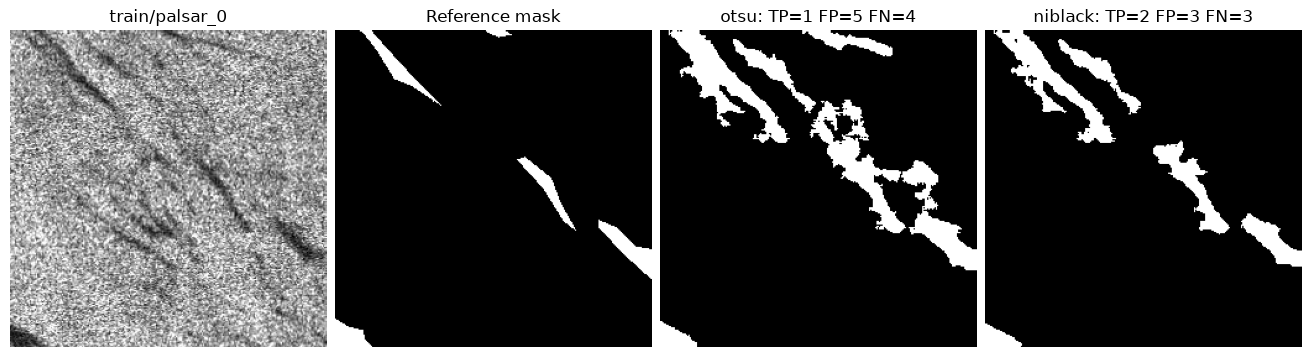

All object and pixel counts match saved results for train/palsar_0


In [3]:
sys.path.insert(0,str(ROOT/'src'))
from sar_oil.data import records,read_pair
from sar_oil.models import RegionModel
from sar_oil.pipeline import predict
from sar_oil.evaluation import counts
row=min(records('external_train'),key=lambda r:r['id'])
image,truth=read_pair(row,128)
fig,axes=plt.subplots(1,4,figsize=(13,4),layout='constrained')
axes[0].imshow(image,cmap='gray',vmin=0,vmax=1);axes[0].set_title(row['id'])
axes[1].imshow(truth,cmap='gray',vmin=0,vmax=1);axes[1].set_title('Reference mask')
for i,(name,model_spec) in enumerate(protocol['models'].items(),2):
    model=RegionModel.load(ROOT/model_spec['model'])
    prediction,_=predict(image,model_spec['config'],model,backend='numpy')
    measured=counts(prediction,truth)
    saved=next(r['counts'] for r in result[name]['per_image'] if r['id']==row['id'])
    assert measured==saved
    axes[i].imshow(prediction,cmap='gray',vmin=0,vmax=1)
    axes[i].set_title(f"{name}: TP={measured['tp']} FP={measured['fp']} FN={measured['fn']}")
for ax in axes: ax.set_axis_off()
plt.show()
print('All object and pixel counts match saved results for',row['id'])

## Giới hạn diễn giải

- Không có ảnh grayscale trùng hoàn toàn với các tập còn lại theo lần kiểm tra;
  điều này không loại trừ patch chồng lấn hoặc cùng cảnh.
- Chưa xác minh lịch sử mọi lần xem thủ công; không gọi đây là kiểm chứng mù.
- Đây là phép thử chuyển sensor, không phải đánh giá Sentinel-1 tại miền Trung.
- Nhãn vẫn là dầu/nền, không có phân loại gió yếu, màng sinh học hay mưa.
- Số liệu nguồn nằm trong `results/sos/external_palsar_train/`; không thay các
  kết quả SOS trước đây hoặc dùng test mới này để lựa chọn lại cấu hình.
